# MediSense-Cardio -- Live Proof Demo (run this live)

**Purpose:** show, live, that the "convert a photo into lines" step genuinely works -- not a
pre-recorded result. You pick any rotation angle out loud. Nothing below is summarized:
every sub-step prints its real, full output AND shows the actual picture at that stage.

1. Rotate a real study page by exactly the angle you picked (the code is never told it).
2. Convert it to grayscale, shown.
3. Find edges (Canny), shown, with the real pixel count.
4. Find every straight line in those edges (Hough), EVERY line's coordinates and angle printed,
   not just a count, and drawn on the picture.
5. Combine all those individual angles into one answer.
6. Compare that answer to the angle you picked.


## Step 1: mount Drive and load one real study page


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, glob
STUDY_DIR = '/content/drive/MyDrive/MediSense-Cardio-Study'
CLEAN_DIR = f'{STUDY_DIR}/images_clean'
clean_files = sorted(glob.glob(f'{CLEAN_DIR}/*.png'))
print(f'{len(clean_files)} clean study images found.')
assert len(clean_files) > 0, 'No clean images found -- check Drive access.'
IMG_PATH = clean_files[0]
print('Using:', IMG_PATH)


Mounted at /content/drive
500 clean study images found.
Using: /content/drive/MyDrive/MediSense-Cardio-Study/images_clean/00053_lr-0.png


## Step 2: the demo function -- every sub-step shown in full, plus the picture at each stage


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def rotate_by_any_angle(img, angle_deg):
    h, w = img.shape[:2]
    center = (w / 2, h / 2)
    M = cv2.getRotationMatrix2D(center, angle_deg, 1.0)
    return cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=(255, 255, 255))

def run(angle):
    print('#'*70); print(f'# NEW TEST: the chosen angle = {angle} degrees'); print('#'*70)

    print('\n--- Step 0: start from a real, undamaged ECG page, then rotate it ---')
    img = cv2.imread(IMG_PATH)
    print(f'Loaded {IMG_PATH}, size {img.shape[1]} x {img.shape[0]}')
    rotated = rotate_by_any_angle(img, float(angle))
    print(f'Applied a rotation of exactly {angle} degrees.')

    print('\n--- Step 1a: convert to grayscale ---')
    gray = cv2.cvtColor(rotated, cv2.COLOR_BGR2GRAY)
    print(f'Brightness range: {int(gray.min())} (darkest) to {int(gray.max())} (brightest)')

    print('\n--- Step 1b: find edges (Canny) ---')
    edges = cv2.Canny(gray, 50, 150)
    n_edge_px = int((edges > 0).sum()); total_px = edges.size
    print(f'{n_edge_px:,} of {total_px:,} pixels marked as an edge ({100*n_edge_px/total_px:.2f}%)')

    print('\n--- Step 1c: find every straight line among those edges (Hough) ---')
    min_len = int(0.3 * gray.shape[1])
    print(f'Rule: only keep lines at least {min_len}px long (30% of the {gray.shape[1]}px width)')
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=100, minLineLength=min_len, maxLineGap=10)
    n_lines = 0 if lines is None else len(lines)
    print(f'Lines found and kept: {n_lines}')

    fig, axs = plt.subplots(1, 4, figsize=(22, 6))
    axs[0].imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB)); axs[0].set_title(f'0: rotated {angle} deg'); axs[0].axis('off')
    axs[1].imshow(gray, cmap='gray'); axs[1].set_title('1a: grayscale'); axs[1].axis('off')
    axs[2].imshow(edges, cmap='gray'); axs[2].set_title('1b: edges (Canny)'); axs[2].axis('off')

    if lines is None or n_lines < 3:
        axs[3].imshow(cv2.cvtColor(rotated, cv2.COLOR_BGR2RGB)); axs[3].set_title('1c: no lines survived'); axs[3].axis('off')
        plt.tight_layout(); plt.show()
        print('\nToo few long lines survived at this exact angle -- a known, honest limitation:')
        print('some specific rotations split the grid lines into pieces too short to pass the rule.')
        print('Try a slightly different number.')
        return

    lines_arr = lines.reshape(-1, 4) if lines.ndim == 3 else lines
    print(f"\n{'line #':<8}{'point 1':<16}{'point 2':<16}{'raw angle':<12}{'deviation'}")
    angles = []
    annotated = rotated.copy()
    for i, (x1, y1, x2, y2) in enumerate(lines_arr):
        a = np.degrees(np.arctan2(y2 - y1, x2 - x1)) % 180
        dev = a % 90; dev = min(dev, 90 - dev)
        angles.append(dev)
        print(f'{i:<8}{str((x1,y1)):<16}{str((x2,y2)):<16}{a:<12.3f}{dev:.3f}')
        cv2.line(annotated, (x1, y1), (x2, y2), (255, 0, 0), 4)
    axs[3].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)); axs[3].set_title(f'1c: {n_lines} lines found'); axs[3].axis('off')
    plt.tight_layout(); plt.show()

    print('\n--- Step 2: combine all the individual line measurements into one answer ---')
    print(f'All {n_lines} individual measurements:')
    print([round(a, 3) for a in angles])
    measured = float(np.median(angles))
    print(f'\nMedian of these {n_lines} numbers = {measured:.3f} degrees')

    print('\n--- Step 3: compare to what you typed in ---')
    expected = abs(float(angle)) % 90
    expected = min(expected, 90 - expected)
    print(f'You typed in:  {angle} degrees')
    print(f'Code measured:        {measured:.3f} degrees')
    print('(the detector reports HOW tilted, not which direction -- +/- the same amount look identical)')
    print(f'Difference:           {abs(expected - measured):.3f} degrees')


## Step 3: run it -- type an angle below and re-run this cell for each one
Change `ANGLE` to whatever you say (e.g. `7`, `-6`, `3.5`, `19`), then run this cell.
Run it again with a new value for as many angles as you want to try.


######################################################################
# NEW TEST: the chosen angle = 7 degrees
######################################################################

--- Step 0: start from a real, undamaged ECG page, then rotate it ---
Loaded /content/drive/MyDrive/MediSense-Cardio-Study/images_clean/00053_lr-0.png, size 2200 x 1700
Applied a rotation of exactly 7 degrees.

--- Step 1a: convert to grayscale ---
Brightness range: 0 (darkest) to 255 (brightest)

--- Step 1b: find edges (Canny) ---
380,332 of 3,740,000 pixels marked as an edge (10.17%)

--- Step 1c: find every straight line among those edges (Hough) ---
Rule: only keep lines at least 660px long (30% of the 2200px width)
Lines found and kept: 233

line #  point 1         point 2         raw angle   deviation
0       (np.int32(0), np.int32(811))(np.int32(2171), np.int32(544))172.989     7.011
1       (np.int32(198), np.int32(1699))(np.int32(2197), np.int32(1454))173.013     6.987
2       (np.int32(39), np.

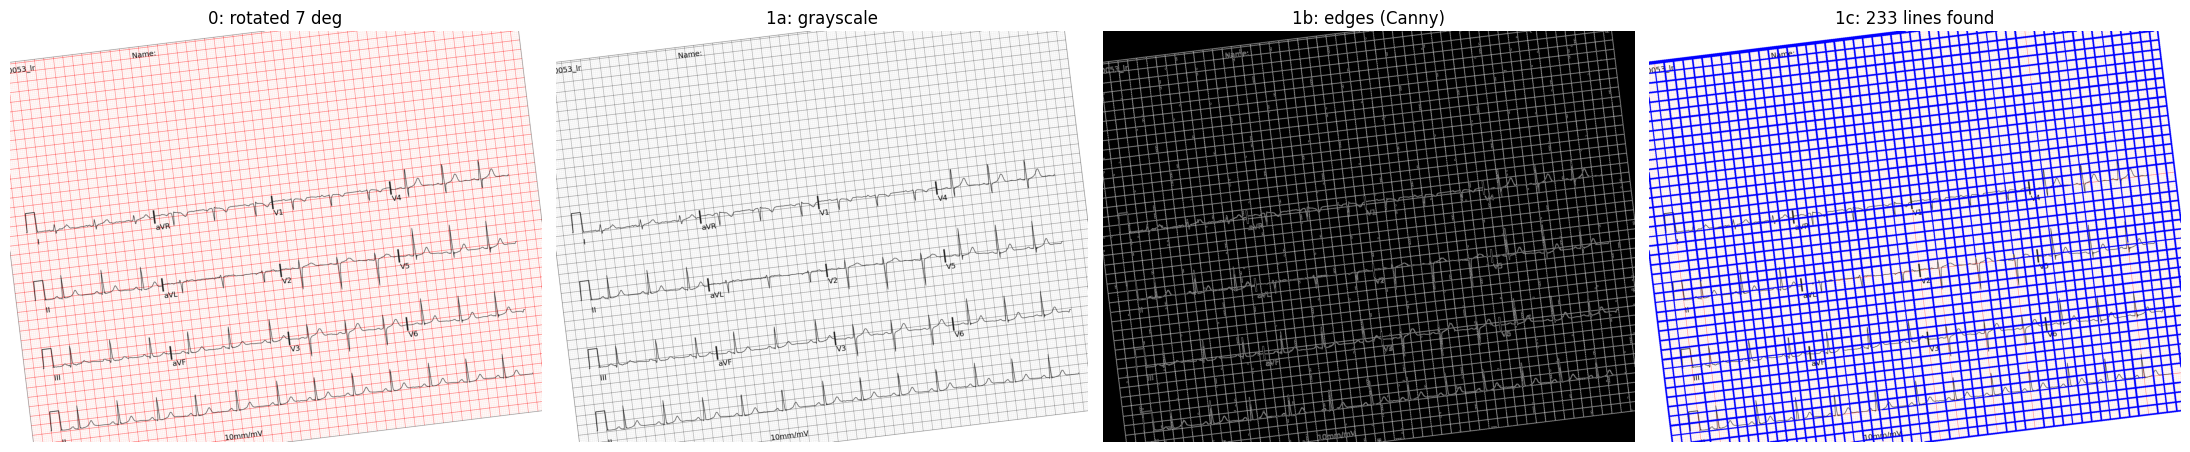


--- Step 2: combine all the individual line measurements into one answer ---
All 233 individual measurements:
[np.float64(7.011), np.float64(6.987), np.float64(6.994), np.float64(7.018), np.float64(6.993), np.float64(7.007), np.float64(6.996), np.float64(6.993), np.float64(7.005), np.float64(7.009), np.float64(7.004), np.float64(6.995), np.float64(6.995), np.float64(6.979), np.float64(7.009), np.float64(6.996), np.float64(6.991), np.float64(6.994), np.float64(7.0), np.float64(7.017), np.float64(6.996), np.float64(6.998), np.float64(6.998), np.float64(7.004), np.float64(7.0), np.float64(6.996), np.float64(6.993), np.float64(6.999), np.float64(6.988), np.float64(7.015), np.float64(6.976), np.float64(6.988), np.float64(7.001), np.float64(6.978), np.float64(6.985), np.float64(7.009), np.float64(7.012), np.float64(7.01), np.float64(6.979), np.float64(6.975), np.float64(7.005), np.float64(6.99), np.float64(7.007), np.float64(7.012), np.float64(7.01), np.float64(7.001), np.float64(6.993), np

In [3]:
ANGLE = 7  # <-- change this to whatever you pick, then re-run this cell
run(ANGLE)
